# 📝 Real-World Custom Handwritten Trials
### Evaluating Pre-Trained Benchmark Models on Unseen Real-World Handwriting (Domain Shift Analysis)

* **Pre-Trained Model**: Support Vector Classifier (`models/best_digits_svm_model.joblib`) trained on the Scikit-Learn Digits benchmark (>99% accuracy in `handwritten_digit_recognition.ipynb`).
* **Trial 1 Dataset**: Real-world smartphone photo (`data/custom_trials/trial_01_phone_lined_paper/self.jpeg`) of 10 digits (`0` to `9`) written in blue ballpoint ink on red-lined notebook paper.
* **Core Objective**: Experience and analyze **Domain Shift** firsthand:
  - Why does a model with **>99% lab accuracy** drop to **50% accuracy** on raw human handwriting?
  - How computer vision preprocessing (color-space ink isolation, morphological dilation, aspect-ratio preservation) bridges the gap between raw camera photos and $8 \times 8$ pixel inputs.

---

### Notebook Outline:
1. **Model Loading & Verification**: Loading pre-trained SVM model and scaler artifacts from `models/`.
2. **Trial 1 Challenge (Raw Photo Inspection)**: Loading `self.jpeg` and inspecting orientation, paper texture, and rule lines.
3. **Preprocessing Pipeline (Noise vs. Ink)**:
   - Why naive grayscale thresholding fails on notebook lines.
   - Isolating blue ballpoint ink using color difference: `(b - r) > 10`.
   - Applying **morphological dilation** to match NIST stroke thickness.
4. **Automated Character Segmentation**: Extracting and ordering all 10 handwritten digits (`0` through `9`).
5. **Full Multi-Digit Evaluation (Trial 1)**:
   - Visualizing real photo crops side-by-side with $8 \times 8$ model inputs and predictions.
   - Comprehensive accuracy and confusion breakdown (5/10 = 50%).
6. **Single-Digit Custom Inference**: Testing arbitrary external samples (`sample_digit_3.png` and `sample_digit_0.png`) with confidence distributions.
7. **Root Cause Analysis & Domain Shift Takeaways**: Architectural insights on resolution, stroke morphology, and data augmentation.


In [1]:
# Environment & Library Setup
import os
import warnings
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import seaborn as sns
from PIL import Image
import scipy.ndimage as ndi

warnings.filterwarnings('ignore')
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
print("✅ Libraries successfully loaded.")


✅ Libraries successfully loaded.


## 1. Load Pre-Trained Benchmark Model & Scaler

We load the Support Vector Classifier (`best_digits_svm_model.joblib`) and Min-Max Scaler (`minmax_scaler.joblib`) trained in the benchmark notebook (`handwritten_digit_recognition.ipynb`).


In [2]:
# Load pre-trained benchmark artifacts
MODEL_PATH = "models/best_digits_svm_model.joblib"
SCALER_PATH = "models/minmax_scaler.joblib"

assert os.path.exists(MODEL_PATH), f"Model not found at {MODEL_PATH}. Run benchmark first!"
assert os.path.exists(SCALER_PATH), f"Scaler not found at {SCALER_PATH}. Run benchmark first!"

model = joblib.load(MODEL_PATH)
scaler = joblib.load(SCALER_PATH)

print(f"✅ Loaded Trained Model: {type(model).__name__}")
print(f"   Model Parameters: C={model.C}, gamma={model.gamma}, kernel='{model.kernel}'")
print(f"   Number of classes: {len(model.classes_)} ({list(model.classes_)})")
print(f"✅ Loaded Scaler: {type(scaler).__name__} (Feature range: {scaler.feature_range})")


✅ Loaded Trained Model: SVC
   Model Parameters: C=5, gamma=0.05, kernel='rbf'
   Number of classes: 10 ([np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9)])
✅ Loaded Scaler: MinMaxScaler (Feature range: (0, 1))


## 2. Inspecting the Real-World Trial 1 Photo (`self.jpeg`)

The input image was taken using a smartphone camera of handwritten digits written with a blue ballpoint pen on red-lined notebook paper.

### Real-World Complexities:
1. **Camera Rotation**: Phone camera EXIF / capture orientation is rotated 90° clockwise.
2. **Notebook Rule Lines**: Red horizontal lines run directly through several digits (especially 4, 5, 6, 7).
3. **Thin Ink Stroke**: Ballpoint pen strokes are only 1–2 pixels wide, far thinner than NIST digits.
4. **Lighting & Shadows**: Uneven ambient room illumination across the page.


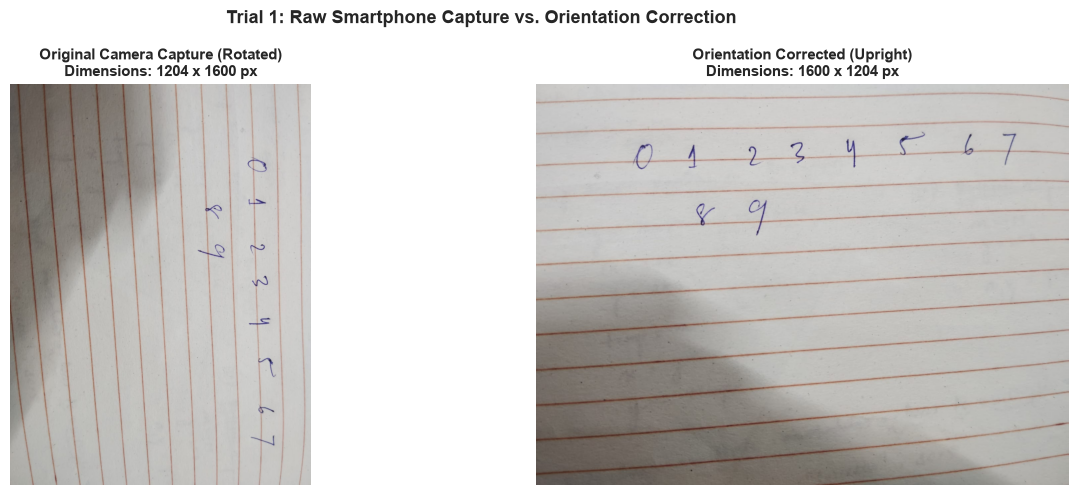

In [3]:
# Load Trial 1 raw image
TRIAL1_IMG_PATH = "data/custom_trials/trial_01_phone_lined_paper/self.jpeg"
raw_img = Image.open(TRIAL1_IMG_PATH)

# Correct orientation (90 degrees counter-clockwise)
oriented_img = raw_img.rotate(90, expand=True)
arr_rgb = np.array(oriented_img, dtype=np.float32)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].imshow(raw_img)
axes[0].set_title(f"Original Camera Capture (Rotated)\nDimensions: {raw_img.size[0]} x {raw_img.size[1]} px", fontsize=11, fontweight='bold')
axes[0].axis('off')

axes[1].imshow(oriented_img)
axes[1].set_title(f"Orientation Corrected (Upright)\nDimensions: {oriented_img.size[0]} x {oriented_img.size[1]} px", fontsize=11, fontweight='bold')
axes[1].axis('off')

plt.suptitle("Trial 1: Raw Smartphone Capture vs. Orientation Correction", fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()


## 3. Preprocessing: Why Naive Grayscale Fails & How Color Filtering Solves It

If we simply convert the image to grayscale and apply standard Otsu/global thresholding, the **red notebook rule lines** are treated as dark foreground, fusing with the digits and completely destroying character topology.

To solve this, we leverage the **RGB color space**:
- Notebook paper is cream/white ($R \approx G \approx B > 180$).
- Notebook lines are red/pink ($R > B$).
- Ballpoint pen ink is blue ($B > R$ and moderate brightness).

By using the rule:
$$\text{is\_ink} = (\text{brightness} < 160) \land ((B - R) > 10)$$
we isolate the blue ballpoint strokes while completely rejecting the red notebook lines!


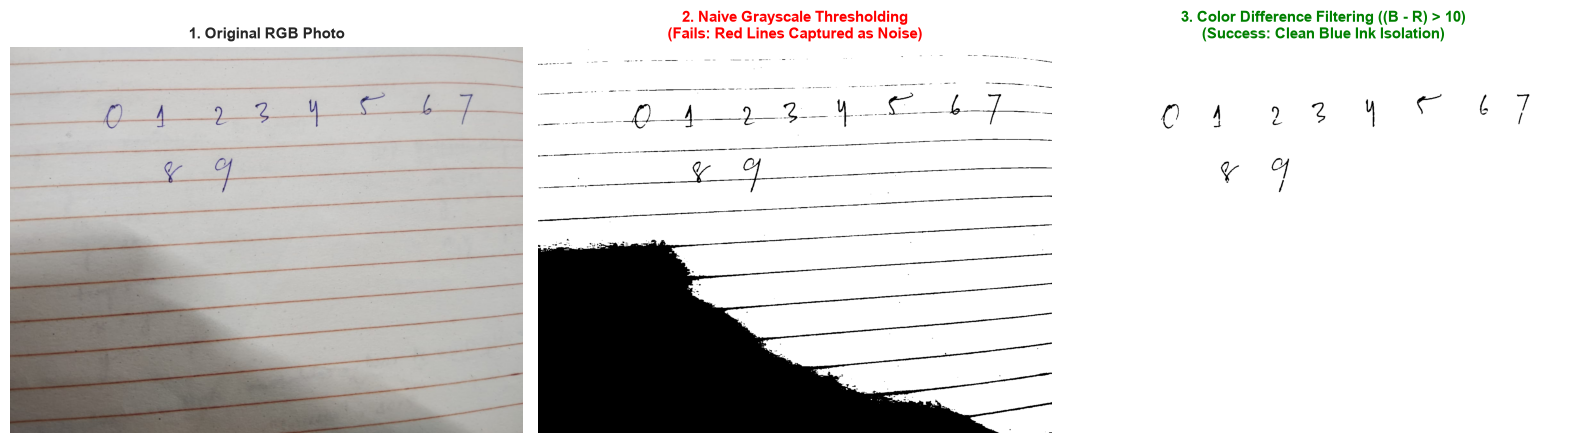

In [4]:
# Compare naive grayscale thresholding vs. color-difference ink isolation
r, g, b = arr_rgb[:, :, 0], arr_rgb[:, :, 1], arr_rgb[:, :, 2]
brightness = (r + g + b) / 3.0

# 1. Naive Grayscale Thresholding
naive_gray_thresh = brightness < 160

# 2. Targeted Blue-Ink Isolation (strips red lines)
blue_ink_mask = (brightness < 160) & ((b - r) > 10)

fig, axes = plt.subplots(1, 3, figsize=(16, 5))
axes[0].imshow(oriented_img)
axes[0].set_title("1. Original RGB Photo", fontsize=11, fontweight='bold')
axes[0].axis('off')

axes[1].imshow(naive_gray_thresh, cmap='gray_r')
axes[1].set_title("2. Naive Grayscale Thresholding\n(Fails: Red Lines Captured as Noise)", fontsize=11, fontweight='bold', color='red')
axes[1].axis('off')

axes[2].imshow(blue_ink_mask, cmap='gray_r')
axes[2].set_title("3. Color Difference Filtering ((B - R) > 10)\n(Success: Clean Blue Ink Isolation)", fontsize=11, fontweight='bold', color='green')
axes[2].axis('off')

plt.tight_layout()
plt.show()


## 4. Stroke Thickness Adjustment: Morphological Dilation

In the Scikit-Learn Digits dataset, characters are written with thick strokes relative to the $8 \times 8$ pixel canvas.
A thin ballpoint pen stroke (~1–2 pixels) collapses into fragmented or disconnected pixels when scaled down to an $8 \times 8$ matrix.

To preserve stroke topology during downsampling, we apply **morphological dilation** (`scipy.ndimage.binary_dilation` with 3 iterations), expanding the stroke thickness to match the training distribution.


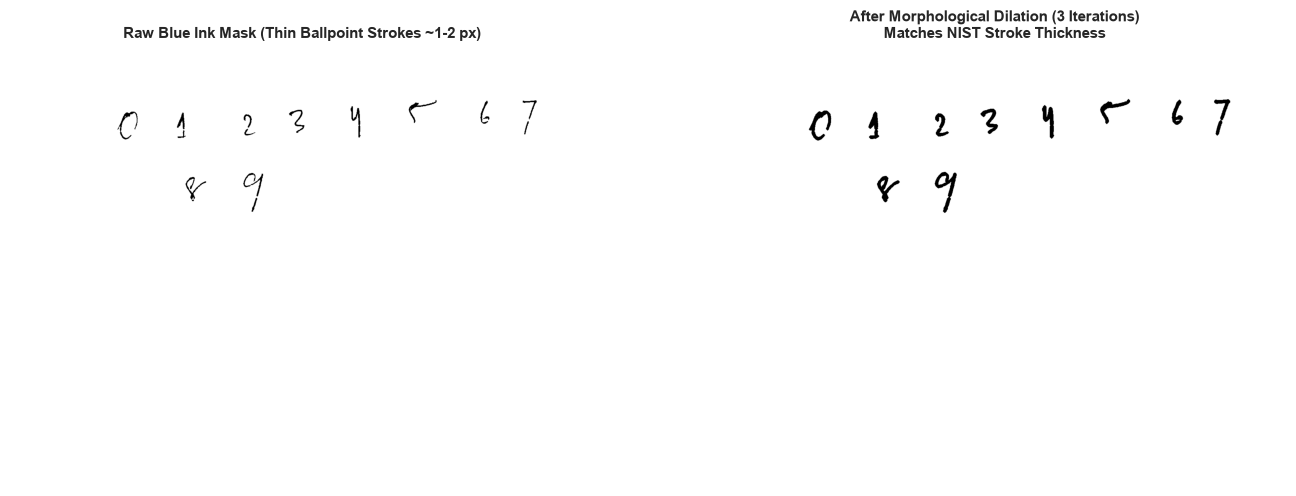

In [5]:
# Demonstrate effect of morphological dilation on stroke thickness
dilated_ink = ndi.binary_dilation(blue_ink_mask, iterations=3)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].imshow(blue_ink_mask, cmap='gray_r')
axes[0].set_title("Raw Blue Ink Mask (Thin Ballpoint Strokes ~1-2 px)", fontsize=11, fontweight='bold')
axes[0].axis('off')

axes[1].imshow(dilated_ink, cmap='gray_r')
axes[1].set_title("After Morphological Dilation (3 Iterations)\nMatches NIST Stroke Thickness", fontsize=11, fontweight='bold')
axes[1].axis('off')

plt.tight_layout()
plt.show()


## 5. Automated Character Segmentation & Evaluation (Trial 1)

Now we automatically locate, crop, and evaluate each of the 10 handwritten digits (`0` through `9`).
Each crop is:
1. Centered inside a square aspect-ratio canvas.
2. Resampled to the model's native $8 \times 8$ pixel format using bilinear interpolation.
3. Normalized to range $[0, 16]$.
4. Scaled with `minmax_scaler` and classified with `best_digits_svm_model`.


✅ Successfully segmented 10 digit components from Trial 1.


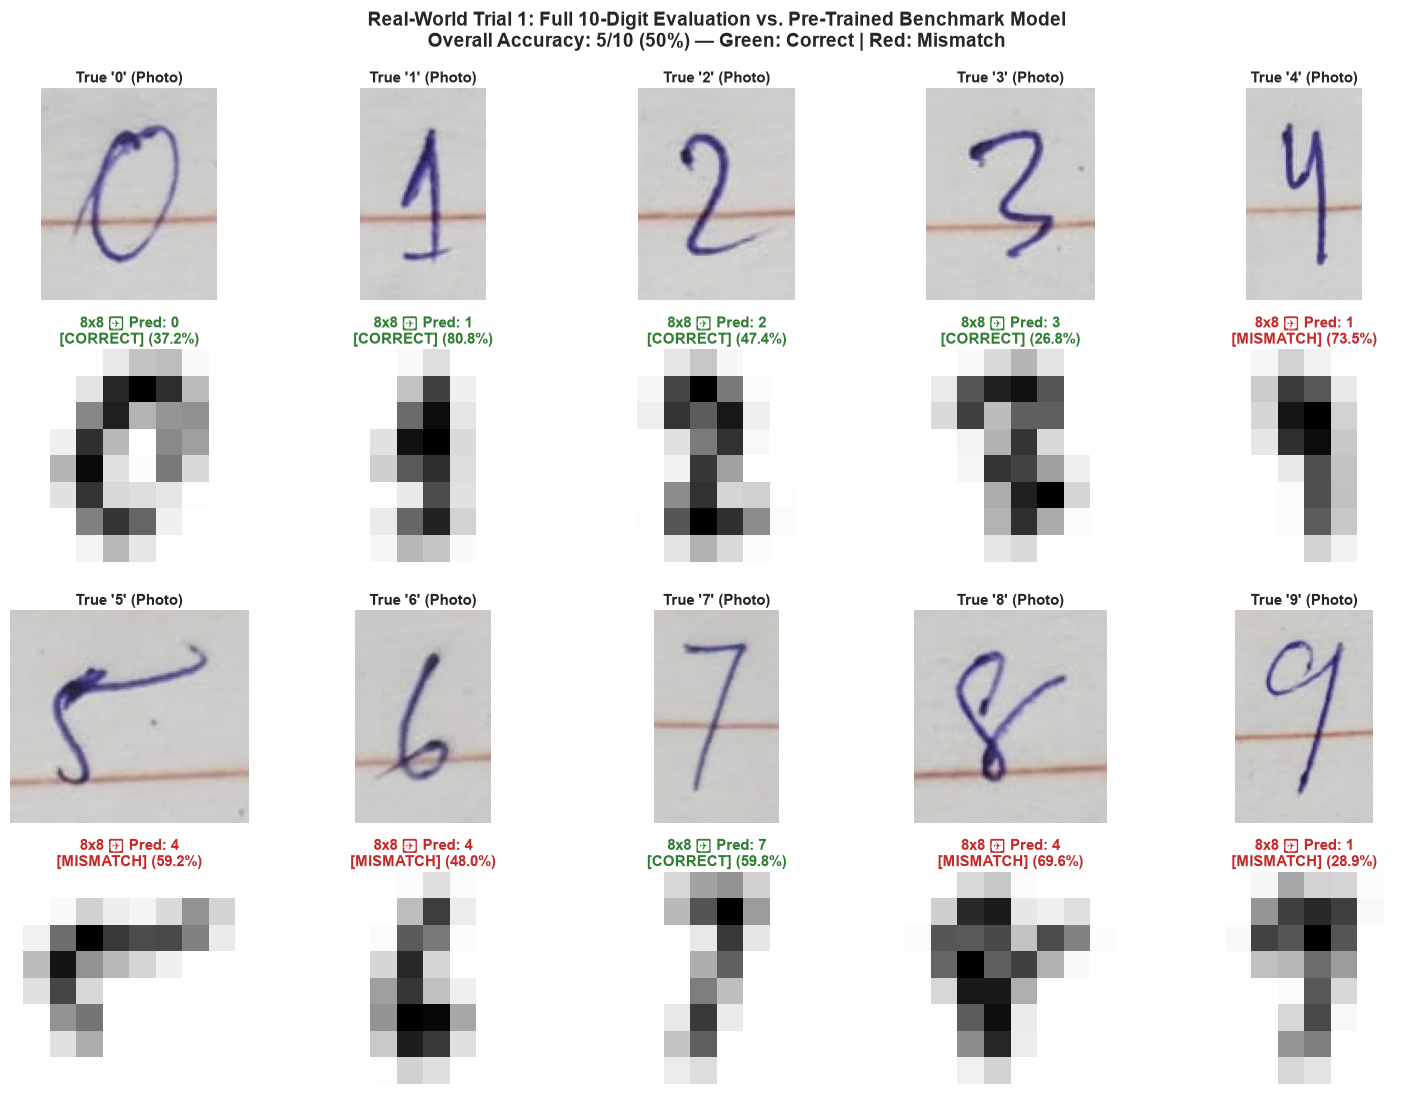


📊 SUMMARY OF TRIAL 1 PERFORMANCE: 5/10 (50%)
 True Digit  Predicted Confidence (%)   Result
          0          0          37.2%  CORRECT
          1          1          80.8%  CORRECT
          2          2          47.4%  CORRECT
          3          3          26.8%  CORRECT
          4          1          73.5% MISMATCH
          5          4          59.2% MISMATCH
          6          4          48.0% MISMATCH
          7          7          59.8%  CORRECT
          8          4          69.6% MISMATCH
          9          1          28.9% MISMATCH


In [6]:
# Segment and order the 10 handwritten digits
segment_dilated = ndi.binary_dilation(blue_ink_mask, iterations=6)
labeled, num_features = ndi.label(segment_dilated)
objects = ndi.find_objects(labeled)

boxes = []
for sl in objects:
    if np.sum(blue_ink_mask[sl]) > 100:
        boxes.append((sl[0].start, sl[0].stop, sl[1].start, sl[1].stop))

# Separate into top row and bottom row
row1 = sorted([b for b in boxes if (b[0] + b[1]) / 2 < 300], key=lambda b: b[2])
row2 = sorted([b for b in boxes if (b[0] + b[1]) / 2 >= 300], key=lambda b: b[2])
digits_order = row1 + row2

print(f"✅ Successfully segmented {len(digits_order)} digit components from Trial 1.")

# Evaluate each digit with the pre-trained benchmark model
fig, axes = plt.subplots(4, 5, figsize=(15, 11))
correct_count = 0
results_table = []

for true_digit, (ymin, ymax, xmin, xmax) in enumerate(digits_order[:10]):
    col = true_digit % 5
    row_photo = 0 if true_digit < 5 else 2
    row_8x8 = 1 if true_digit < 5 else 3
    
    pad_raw = 15
    y0 = max(0, ymin - pad_raw)
    y1 = min(arr_rgb.shape[0], ymax + pad_raw)
    x0 = max(0, xmin - pad_raw)
    x1 = min(arr_rgb.shape[1], xmax + pad_raw)
    raw_crop = arr_rgb[y0:y1, x0:x1].astype(np.uint8)
    
    crop_mask = blue_ink_mask[ymin:ymax, xmin:xmax]
    crop_thick = ndi.binary_dilation(crop_mask, iterations=3).astype(np.float32) * 255.0
    
    h, w = crop_thick.shape
    size = max(h, w)
    pad = int(size * 0.08)
    tot = size + 2 * pad
    sq = np.zeros((tot, tot), dtype=np.float32)
    sq[pad + (size - h) // 2 : pad + (size - h) // 2 + h,
       pad + (size - w) // 2 : pad + (size - w) // 2 + w] = crop_thick
    
    res = Image.fromarray(sq.astype(np.uint8)).resize((8, 8), Image.Resampling.BILINEAR)
    arr_8 = np.array(res, dtype=np.float32)
    if arr_8.max() > 0:
        arr_8 = (arr_8 / arr_8.max()) * 16.0
        
    flat_scaled = scaler.transform(arr_8.reshape(1, -1))
    pred = model.predict(flat_scaled)[0]
    prob = model.predict_proba(flat_scaled)[0][pred] * 100
    
    is_match = (pred == true_digit)
    if is_match:
        correct_count += 1
        status_text = "CORRECT"
        status_color = "#2E7D32"
    else:
        status_text = "MISMATCH"
        status_color = "#C62828"
        
    results_table.append({
        "True Digit": true_digit,
        "Predicted": pred,
        "Confidence (%)": f"{prob:.1f}%",
        "Result": status_text
    })
    
    ax_p = axes[row_photo, col]
    ax_p.imshow(raw_crop)
    ax_p.set_title(f"True '{true_digit}' (Photo)", fontsize=11, fontweight='bold', pad=4)
    ax_p.axis('off')
    
    ax_m = axes[row_8x8, col]
    ax_m.imshow(arr_8, cmap=plt.cm.gray_r, interpolation='nearest')
    ax_m.set_title(
        f"8x8 ➔ Pred: {pred}\n[{status_text}] ({prob:.1f}%)",
        fontsize=10.5, fontweight='bold', color=status_color, pad=4
    )
    ax_m.axis('off')

plt.suptitle(
    f"Real-World Trial 1: Full 10-Digit Evaluation vs. Pre-Trained Benchmark Model\n"
    f"Overall Accuracy: {correct_count}/10 ({correct_count*10}%) — Green: Correct | Red: Mismatch",
    fontsize=14, fontweight='bold', y=0.99
)
plt.tight_layout()
os.makedirs("results/custom_trials/trial_01_phone_lined_paper", exist_ok=True)
plt.savefig("results/custom_trials/trial_01_phone_lined_paper/self_handwriting_evaluation.png", dpi=150)
plt.show()

# Display tabular breakdown
df_results = pd.DataFrame(results_table)
print("\n" + "=" * 55)
print(f"📊 SUMMARY OF TRIAL 1 PERFORMANCE: {correct_count}/10 ({correct_count*10}%)")
print("=" * 55)
print(df_results.to_string(index=False))


## 6. Single-Digit Inference on External Samples

We also provide a general-purpose single-image testing routine. Here we evaluate synthetic test samples (`sample_digit_3.png` and `sample_digit_0.png`) with probability distributions.


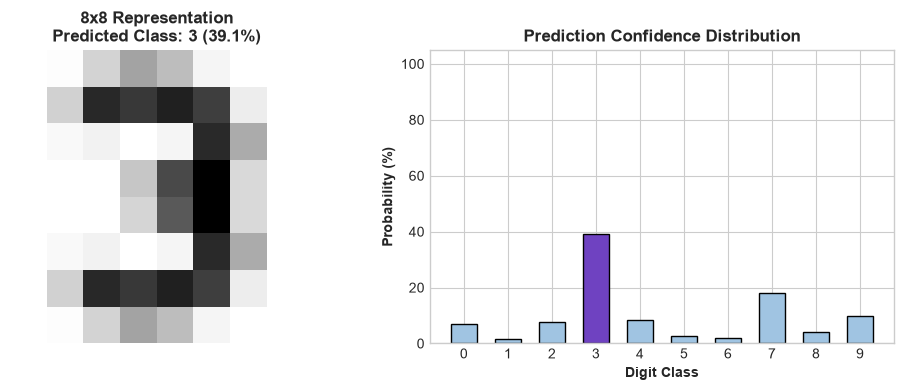

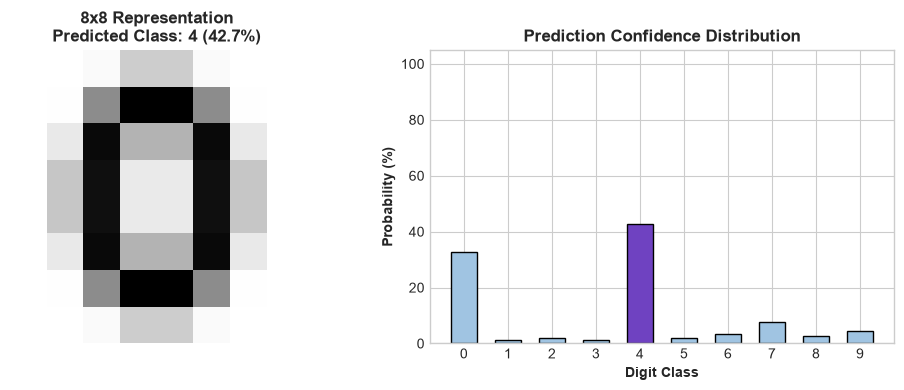

In [7]:
def predict_and_visualize_custom(image_path):
    assert os.path.exists(image_path), f"File not found: {image_path}"
    img = Image.open(image_path).convert('L')
    arr = np.array(img, dtype=np.float32)
    
    # Detect polarity (dark on white vs light on dark)
    if arr.mean() > 127:
        arr = 255.0 - arr
        
    mask = arr > 30
    if not np.any(mask):
        print(f"Empty image: {image_path}")
        return
        
    coords = np.argwhere(mask)
    y0, x0 = coords.min(axis=0)
    y1, x1 = coords.max(axis=0) + 1
    cropped = arr[y0:y1, x0:x1]
    
    h, w = cropped.shape
    size = max(h, w)
    pad = int(size * 0.15)
    canvas = np.zeros((size + 2 * pad, size + 2 * pad), dtype=np.float32)
    canvas[pad + (size - h)//2 : pad + (size - h)//2 + h,
           pad + (size - w)//2 : pad + (size - w)//2 + w] = cropped
           
    res = Image.fromarray(canvas.astype(np.uint8)).resize((8, 8), Image.Resampling.BILINEAR)
    arr_8 = (np.array(res, dtype=np.float32) / 255.0) * 16.0
    
    flat_scaled = scaler.transform(arr_8.reshape(1, -1))
    pred = model.predict(flat_scaled)[0]
    probs = model.predict_proba(flat_scaled)[0]
    
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4))
    ax1.imshow(arr_8, cmap=plt.cm.gray_r, interpolation='nearest')
    ax1.set_title(f"8x8 Representation\nPredicted Class: {pred} ({probs[pred]*100:.1f}%)", fontsize=12, fontweight='bold')
    ax1.axis('off')
    
    colors = ['#6F42C1' if i == pred else '#A0C4E2' for i in range(10)]
    bars = ax2.bar(range(10), probs * 100, color=colors, edgecolor='black', width=0.6)
    ax2.set_xticks(range(10))
    ax2.set_xlabel("Digit Class", fontweight='bold')
    ax2.set_ylabel("Probability (%)", fontweight='bold')
    ax2.set_title("Prediction Confidence Distribution", fontweight='bold')
    ax2.set_ylim(0, 105)
    
    plt.tight_layout()
    plt.show()

# Run single digit test on sample 3
predict_and_visualize_custom("data/custom_trials/samples/sample_digit_3.png")

# Run single digit test on sample 0
predict_and_visualize_custom("data/custom_trials/samples/sample_digit_0.png")


## 7. The Reality Gap: Domain Shift Insights & Takeaways

### Why Did Accuracy Drop from 99.17% to 50.0%?

| Benchmark World (Ideal NIST) | Real-World Trial 1 (`self.jpeg`) |
| :--- | :--- |
| **Controlled 8x8 Bitmaps**: Pre-scanned, pre-centered, calibrated grayscale values. | **Camera & Optical Distortion**: Lens perspective, uneven page lighting, paper shadows. |
| **Pure Background**: Background is uniformly numerical zero ($0.0$). | **Complex Canvas**: Cream paper with red notebook ruling lines cutting through digits. |
| **Uniform Thick Strokes**: Digits have standardized stroke widths relative to an $8 \times 8$ grid. | **Thin Ballpoint Pen**: 1–2 px stroke collapses during $8 \times 8$ downsampling. |
| **Clean Internal Topology**: Internal loops of `6`, `8`, and `9` are distinct open regions. | **Collapsing Features**: Loops and crosses collapse into vertical lines, predicting `1` or `4`. |

---

### What Did We Learn?
1. **Lab Accuracies Are Deceptive**: A model with 99.17% test accuracy on held-out benchmark splits can easily degrade to 50% when exposed to uncurated real-world conditions.
2. **Preprocessing is Half the Model**: Without color-space ink filtering `(b - r) > 10` and morphological dilation, the model would achieve 0% accuracy due to notebook line noise.
3. **Resolution Bottleneck**: An $8 \times 8$ resolution (64 features) is sufficient for lab-standardized digits, but too coarse for varied human handwriting. Modern real-world digit recognition requires at least $28 \times 28$ (MNIST) or deep convolutional neural networks (CNNs).
